---
This is some simpler fitting of the PDE data. It is very clunky, and motivates why we had to build some custom fitting tools, to avoid writing a million different functions

This showed our poor sensitivity to the oxide thickness, and that it may in fact be much less than 100nm

This does not use any external fitting tools

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling


------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


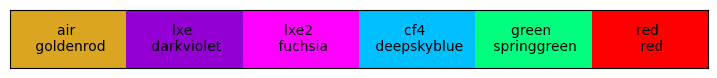

In [1]:
from GenPaths import * # this provides PROPATH which can help load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
from PDEhelpers.PNJunction import *
import PDEhelpers.PDEStyle as MS

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [2]:
file_path = "../../veraData/HPK_IR_PDE-Feb12_2024-Harry.csv"
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())

angles = df['Angle'].unique()
voltages = df['Overvoltage'].unique()

# print("Angles:", angles)
# print("voltages:", voltages)



      Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
2188     799.979     60            6  3.429750e-14  0.041089   0.004239
2189     809.978     60            6  3.299900e-14  0.039534   0.003863
2190     820.008     60            6  3.095340e-14  0.037083   0.003730
2191     830.012     60            6  2.754830e-14  0.033003   0.003196
2192     830.012     60            6  2.754830e-14  0.033003   0.003196
--------------------------
Overvoltage
0    260
1    255
2    255
3    255
4    255
5    255
6    254
7    204
8    200
Name: count, dtype: int64
Angle
0     459
15    459
30    459
45    459
60    357
Name: count, dtype: int64


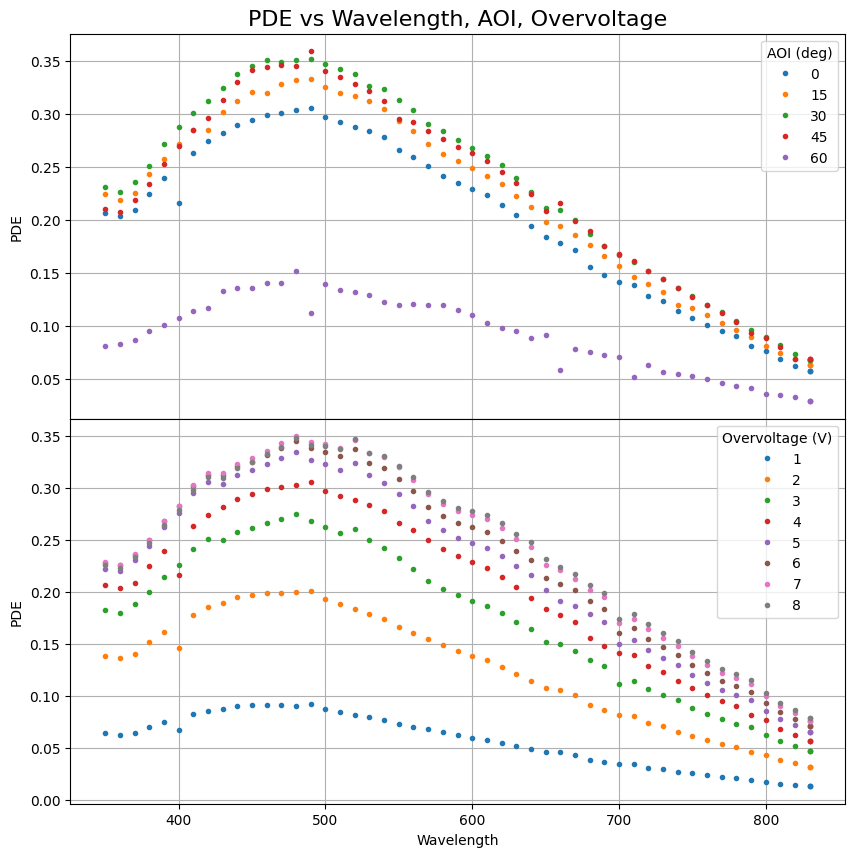

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))

# xv4 = df[df['Overvoltage'] == 4]
for angle in angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 4)]

    dt1.plot(x='Wavelength', y = "PDE", label = f"{angle:0.0f}", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in voltages[1:]:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE", label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
plt.subplots_adjust(hspace=0)
plt.show()

# matrix

---
## PDE fitting v1
still defining PDE equations locally. There are different ways to minimize this and/or create a score statistic

1. least squares
1. chi2 (error!?)


### Coding Strategies
To have control, there are *at least* three methods without resorting to pyroot or something more exotic than scipy
1. wrap the PDE functions with other functions (hard to control other params, need to pass a dict)
2. curve_fit with very small bounds on the 'fixed' parameters. maybe clearest and simplest
3. the dictionairy sorting method done below. confusing but possibly most robust/user friendly if coded properly

In [4]:
from scipy.optimize import minimize
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d
from scipy.ndimage import uniform_filter1d
from scipy.interpolate import interp1d

def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False):
    
    photon = PhotonInfo(wlen, theta1)    
    Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        nyield = (1240/wlen)/3.2
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    if smoothSigma is not None: # expensive but simple/works/robust
        stepPerSigma = 3
        stepSize = smoothSigma / stepPerSigma
        newXVals = np.arange(min(wlen), max(wlen) + stepSize, stepSize)
        fullerPDEVals = PDE_allArgs(newXVals, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma = None)
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=smoothSigma)
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)
        
    return PDE

def xEvenSpacing(center, range, N):
    N = int(N)
    N +=1 if N%2 == 1 else 0 # ensure even spacing
    x = np.linspace(center-range, center+range, N, endpoint=True)
    # if center not in x:
    #     print("ERROR NO X IN XEVENSPACING")
    #     return None
    return x

def orderDict(func, givenDict): # get the dictionary in the order needed for the function
    argsInside = func.__code__.co_varnames[:func.__code__.co_argcount]
    return {key: givenDict[key] for key in argsInside if key in givenDict}

class ParameterMaster:
  pass
pm = ParameterMaster()
pm.staticPars= {"FF":0.6, "theta1":0.0, "dp_star": 4, "Xpn": 2e3, "tOxide": 110, "dw_star": 5e3, "pe": 0.5, "ph": 0.5}
pm.bounds_dict = {"tOxide":(5, 300),
                  "dp_star":(0.0, 100),
                  "Xpn":(0.2e3, 10e3),
                  "dw_star":(1e3, 25e3),
                  "pe":(0.0, 1.0),
                  "ph":(0.0, 1)
                  }

###---------- Wrapped PDE functions ------------###
fixedFF = 0.6

### UV XPn - high voltage: 350-420 nm, 7V, 8V
# free:            dp*, tOxide
# medium (free):   Xpn
# insensitive (fixed):  dw*, pe, ph,  theta1, FF
pm.staticPars_uv_fpe = {"FF":fixedFF, "theta1":0.0, "dw_star": 5e3, "pe":1.0, "ph":0.2}
def PDE_wrapped_uv_fpe(wlen, tOxide, dp_star, Xpn):
    return PDE_allArgs(wlen, tOxide=tOxide, dp_star=dp_star, Xpn=Xpn, **pm.staticPars_uv_fpe)

### UV Pe - lower voltage: 350-420 nm
# free:            pe, dp*, tOxide
# medium (free):   
# insensitive (fixed):  Xpn (from above), dw*, ph, theta1, FF
pm.staticPars_uv_fXpn = {"FF":fixedFF, "theta1":0.0, "dw_star": 5e3, "Xpn":2e3, "ph":0.2}
def PDE_wrapped_uv_fXpn(wlen, tOxide, dp_star, pe):
    return PDE_allArgs(wlen, tOxide=tOxide, dp_star=dp_star, pe=pe, **pm.staticPars_uv_fXpn)

# pm.staticPars_uv = {"FF":fixedFF, "theta1":0.0, "dw_star": 5e3, "ph":0.2}
# def PDE_wrapped_uv(wlen, tOxide, dp_star, Xpn, pe):
#     return PDE_allArgs(wlen, tOxide=tOxide, dp_star=dp_star, Xpn = Xpn, pe=pe, **pm.staticPars_uv)

### Vis: 450-800 nm
# free:                 ph, dw_star, 
# medium (free):        Xpn
# insensitive (fixed):  tOxide, dp*, pe, theta1, FF
pm.staticPars_vis_junction = {"FF":0.6, "theta1":0.0, "tOxide":110, "dp_star": 4, "pe":1.0}
def PDE_wrapped_vis_junction(wlen, Xpn, dw_star, ph):
    return PDE_allArgs(wlen, Xpn=Xpn, dw_star=dw_star, ph=ph, **pm.staticPars_vis_junction)

### Vis: 450-800 nm
# free:                 ph, dw_star, tOxide
# medium (free):        Xpn
# insensitive (fixed):  dp*, pe, theta1, FF
pm.staticPars_vis_fpe1 = {"FF":0.6, "theta1":0.0, "dp_star": 4, "pe":0.5}
def PDE_wrapped_vis1(wlen, tOxide, Xpn, dw_star, ph):
    return PDE_allArgs(wlen, tOxide=tOxide, Xpn=Xpn, dw_star=dw_star, ph=ph, **pm.staticPars_vis_fpe1)


# pm.static_Exp = {"FF":0.6, "theta1":0.0}
# def PDE_wrapped_full(wlen, tOxide, dp_star, Xpn, dw_star, pe, ph):
#     return PDE_allArgs(wlen, tOxide=tOxide, dp_star=dp_star, Xpn=Xpn, dw_star=dw_star, pe=pe, ph=ph, **pm.static_Exp)

print("uv_pe test", PDE_wrapped_uv_fpe(*(420, 110, 4, 2e3)))
print("uv_xpn test", PDE_wrapped_uv_fXpn(*(420, 110, 4, 0.6)))


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
uv_pe test 0.3791073282946917
uv_xpn test 0.22746854091614005


========== Fit 1 ==========


UV fit(fixed pe, IR junction pars) results: [136.05152384   1.24668878 634.11153205]
    tOxide: 136.05  +/- 54.27
    dp_star: 1.25  +/- 4.67
    Xpn: 634.11  +/- 1019.44
Vis fit (fixed pe, dp*, tOxide) results: [1.43209500e+03 2.32134629e+04 1.06514375e-01]
    Xpn: 1432.10  +/- 132.28
    dw_star: 23213.46  +/- 25787.50
    ph: 0.11  +/- 0.04
Free-er Vis fit (fixed pe, dp*) results: [1.35976534e+02 1.43035994e+03 2.31223444e+04 1.06820399e-01]
    tOxide: 135.98  +/- 6.96
    Xpn: 1430.36  +/- 218.68
    dw_star: 23122.34  +/- 28040.44
    ph: 0.11  +/- 0.05

Chi2: 1.39
reduced: 0.03 

--------------------------
========== Fit 2 ==========
UV fit(fixed pe, IR junction pars) results: [261.38739146   1.47748509 355.73732828]
    tOxide: 261.39  +/- 18.11
    dp_star: 1.48  +/- 1.73
    Xpn: 355.74  +/- 233.93
Vis fit (fixed pe, dp*, tOxide) results: [2.00815708e+02 6.13393363e+03 6.24821331e-01]
    Xpn: 200.82  +/- 73.68
    dw_star: 6133.93  +/- 624.45
    ph: 0.62  +/- 0.04
Free-er

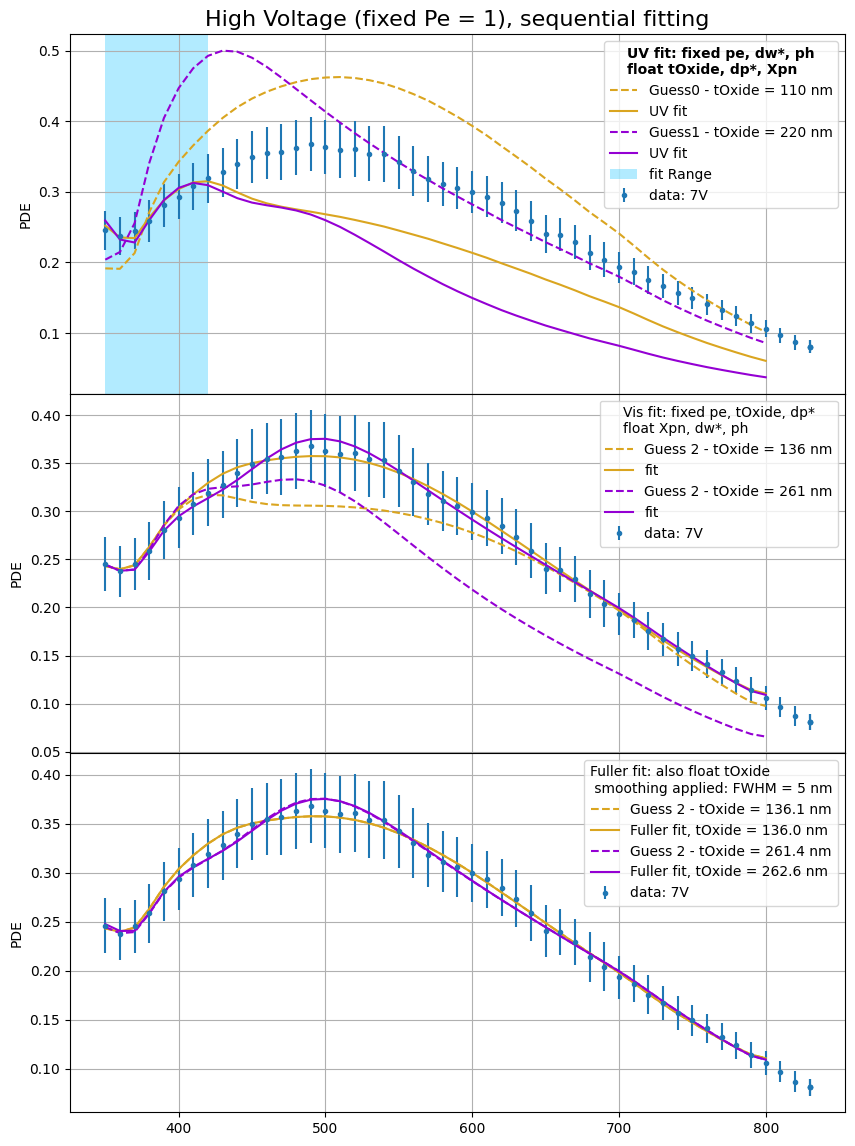

In [5]:
#### 110 nm thickness

# -- load the data -- #
fitAngle = 15
voltages = df['Overvoltage'].unique()[2:]
FFfixed = 0.6
FWHMbeam = 5
sigmaBeam = FWHMbeam / (2 * np.sqrt(2 * np.log(2)))

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize = (10, 14))

## fit options
# cfit_opts = {"maxfev": 10000, "xtol": 1e-6, "ftol": 1e-6, "absolute_sigma":True}
cfit_opts = {"absolute_sigma":True}

for V in voltages[-2:-1]:
    df_fit = df[(df['Angle'] == fitAngle) & (df['Overvoltage'] == V)]
    xData = df_fit['Wavelength']
    yData = df_fit['PDE']
    yErr = df_fit["PDE_error"]
    ax1.errorbar(xData, yData, yerr=yErr, marker = ".", linestyle = "", label = f"data: {V:0.0f}V")
    ax2.errorbar(xData, yData, yerr=yErr, marker = ".", linestyle = "", label = f"data: {V:0.0f}V")
    ax3.errorbar(xData, yData, yerr=yErr, marker = ".", linestyle = "", label = f"data: {V:0.0f}V")

# model breaks after 800
mask_full = (xData < 800)
xData = xData[mask_full]
yData = yData[mask_full]
yErr = yErr[mask_full]

## doing UV fit
mask_uv = (xData < 420)
xData_uv = xData[mask_uv]
yData_uv = yData[mask_uv]
yErr_uv = yErr[mask_uv]

uvFits_fpe = []

for i, tOxide_guess in enumerate([110, 220]):
    
    colMS = ms.allColsStr[i]
    print(f"========== Fit {i+1} ==========")
    
    # ---------------- UV Fit 1 - high voltage - fixed pe ----------------- #
    pm.guessUV_fpe = {"tOxide": tOxide_guess, "dp_star": 3.0, "Xpn": 2e3}
    pm.staticPars_uv_fpe = {"FF":fixedFF, "theta1":fitAngle, "dw_star": 5e3, "pe":1.0, "ph":0.2, "smoothSigma": None}
    
    # pnTest = PNJunction(dp_star = pm.guessUV_fpe["dp_star"], Xpn = pm.guessUV_fpe["Xpn"], dw_star=pm.staticPars_uv_fpe["dw_star"])
    # print(pnTest.calcW_both(PhotonInfo(420, 0)))
    # print(PDE_wrapped_uv_fpe(420, **pm.guessUV_fpe))

    # get the guesses and bounds from the dictionairies
    pGuess_uv_fpe = tuple(pm.guessUV_fpe.values())
    lower_bounds_uv_fpe = [pm.bounds_dict[key][0] for key in pm.guessUV_fpe]
    upper_bounds_uv_fpe = [pm.bounds_dict[key][1] for key in pm.guessUV_fpe]

    # fitting and plotting
    ax1.plot(xData, PDE_wrapped_uv_fpe(xData, *pGuess_uv_fpe), linestyle = "--", color = colMS, label = f"Guess{i} - tOxide = {tOxide_guess:0.0f} nm") # plot guess
    popt_uv_fpe, pcov_uv_fpe = curve_fit(f=PDE_wrapped_uv_fpe, xdata=xData_uv, ydata=yData_uv, sigma = yErr_uv, p0=pGuess_uv_fpe, bounds=(lower_bounds_uv_fpe, upper_bounds_uv_fpe), **cfit_opts)
    # plot the UV fit
    ax1.plot(xData, PDE_wrapped_uv_fpe(xData, *popt_uv_fpe), color = colMS, label = "UV fit")

    # uvFits_fpe.append([popt_uv_fpe, pcov_uv_fpe])
    print("UV fit(fixed pe, IR junction pars) results:", popt_uv_fpe)
    for i, key in enumerate(pm.guessUV_fpe):
        print(f"    {key}: {popt_uv_fpe[i]:0.2f}  +/- {np.sqrt(pcov_uv_fpe[i,i]):0.2f}")    
    fit_tOxide = popt_uv_fpe[0]
    fit_dp_star = popt_uv_fpe[1]
    fit_Xpn = popt_uv_fpe[2]
    
    # ---------------- Full fit - high voltage - fixed pe, tOxide ----------------- #
    pm.guessVis_fpe_junction = {"Xpn": fit_Xpn, "dw_star": pm.staticPars_uv_fpe["dw_star"], "ph":0.4}
    pm.staticPars_vis_junction = {"FF":0.6, "theta1":fitAngle, "tOxide": fit_tOxide, "dp_star": fit_dp_star, "pe":1.0, "smoothSigma": 5} # handed straight to function
    
    pGuess_vis_fpe_junction = tuple(pm.guessVis_fpe_junction.values())
    lower_bounds_vis_fpe_junc = [pm.bounds_dict[key][0] for key in pm.guessVis_fpe_junction]
    upper_bounds_vis_fpe_junc = [pm.bounds_dict[key][1] for key in pm.guessVis_fpe_junction]
    
    ax2.plot(xData, PDE_wrapped_vis_junction(xData, *pGuess_vis_fpe_junction), color = colMS, linestyle = "--", label = f"Guess {i} - tOxide = {fit_tOxide:0.0f} nm") # plot guess
    popt_vis_fpe_junc, pcov_vis_fpe_junc = curve_fit(f=PDE_wrapped_vis_junction, xdata=xData, ydata=yData, sigma = yErr, p0=pGuess_vis_fpe_junction, bounds=(lower_bounds_vis_fpe_junc, upper_bounds_vis_fpe_junc), **cfit_opts)
    ax2.plot(xData, PDE_wrapped_vis_junction(xData, *popt_vis_fpe_junc), color = colMS, label = f"fit")
    
    print("Vis fit (fixed pe, dp*, tOxide) results:", popt_vis_fpe_junc)
    for i, key in enumerate(pm.guessVis_fpe_junction):
        print(f"    {key}: {popt_vis_fpe_junc[i]:0.2f}  +/- {np.sqrt(pcov_vis_fpe_junc[i,i]):0.2f}")
    
    fit2_Xpn = popt_vis_fpe_junc[0]
    fit2_dw_star = popt_vis_fpe_junc[1]
    fit2_ph = popt_vis_fpe_junc[2]
    
    # ---------------- Full Fit 2 - high voltage - fixed pe, float tOxide ----------------- #
    pm.guessVis_fpe1 = {"tOxide":fit_tOxide, "Xpn": fit2_Xpn, "dw_star": fit2_dw_star, "ph": fit2_ph}
    pm.staticPars_vis_fpe1 = {"FF":0.6, "theta1":fitAngle, "dp_star": fit_dp_star, "pe":1.0, "smoothSigma": 5} # handed straight to function
    
    pGuess_vis_fpe1 = tuple(pm.guessVis_fpe1.values())
    lower_bounds_vis_fpe1 = [pm.bounds_dict[key][0] for key in pm.guessVis_fpe1]
    upper_bounds_vis_fpe1 = [pm.bounds_dict[key][1] for key in pm.guessVis_fpe1]
    
    ax3.plot(xData, PDE_wrapped_vis1(xData, *pGuess_vis_fpe1), color = colMS, linestyle = "--", label = f"Guess {i} - tOxide = {fit_tOxide:0.1f} nm") # plot guess
    popt_vis_fpe1, pcov_vis_fpe1 = curve_fit(f=PDE_wrapped_vis1, xdata=xData, ydata=yData, sigma = yErr, p0=pGuess_vis_fpe1, bounds=(lower_bounds_vis_fpe1, upper_bounds_vis_fpe1), **cfit_opts)
    ax3.plot(xData, PDE_wrapped_vis1(xData, *popt_vis_fpe1), color = colMS, label = f"Fuller fit, tOxide = {popt_vis_fpe1[0]:0.1f} nm")
    
    print("Free-er Vis fit (fixed pe, dp*) results:", popt_vis_fpe1)
    for i, key in enumerate(pm.guessVis_fpe1):
        print(f"    {key}: {popt_vis_fpe1[i]:0.2f}  +/- {np.sqrt(pcov_vis_fpe1[i,i]):0.2f}")
    
    chi2 = np.sum((PDE_wrapped_vis1(xData, *popt_vis_fpe1) - yData)**2 / yErr**2)
    chi2_red = chi2 / (len(xData) - len(popt_vis_fpe1))
    
    print(f"\nChi2: {chi2:0.2f}\nreduced: {chi2_red:0.2f} \n")
    print("--------------------------")
 
    
ax1.set_title("High Voltage (fixed Pe = 1), sequential fitting", fontsize = 16)

ax1.axvspan(min(xData_uv), max(xData_uv), facecolor=ms.cf4.col, alpha=0.3, label = "fit Range")
leg = ax1.legend(title = "UV fit: fixed pe, dw*, ph\nfloat tOxide, dp*, Xpn")
plt.setp(leg.get_title(), weight='bold')

leg = ax2.legend(title = "Vis fit: fixed pe, tOxide, dp*\nfloat Xpn, dw*, ph")

ax3.legend(title = f"Fuller fit: also float tOxide\n smoothing applied: FWHM = {FWHMbeam:0.0f} nm")

axes = [ax1, ax2, ax3]
for ax in axes:
    ax.grid()
    ax.set_ylabel("PDE")
    
# plt.tight_layout()
plt.subplots_adjust(hspace=0)
plt.show()

some things are confusing

we are so sensitive to tOxide

Xpn should be varied in both? its close to mattering for UV. lets constrain UV fit to 420

moving to 420 makes Xpn fit go crazy. constrain it


impossible to hit efficiency needed at 350 without dp* basically zero

start with higher voltage data

doing gaussian smoothing for unequal or misc. x spacing is not trivial. supposed to interpolate or something. Id rather do a homemade convolution in the function

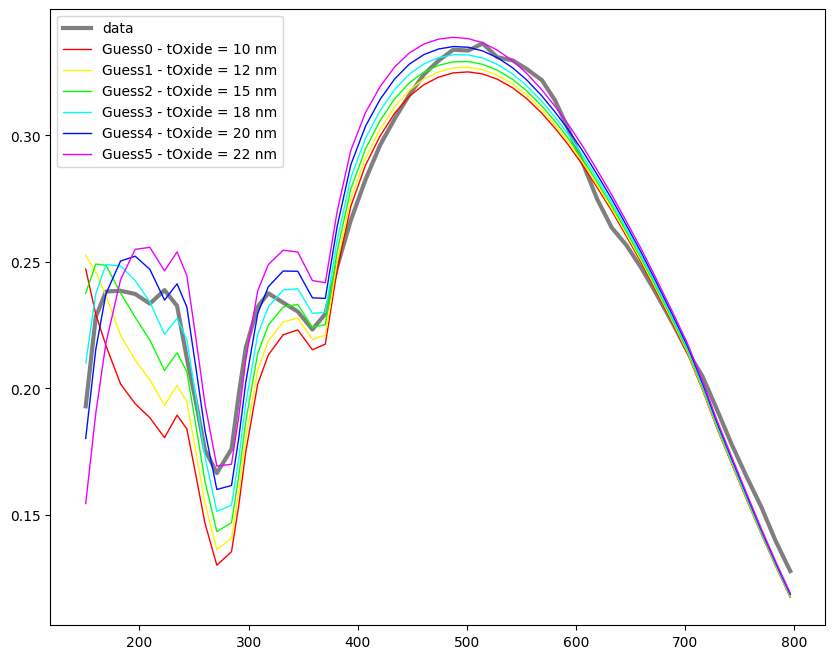

In [6]:
from cycler import cycler
fig, ax1= plt.subplots(1, 1, sharex=True, figsize = (10, 8))

## fit options
cfit_opts = {"maxfev": 10000, "xtol": 1e-6, "ftol": 1e-6, "absolute_sigma":True}

thickList = np.arange(80, 120, 20)
thickList = np.arange(10, 25, 2.5)

# colors
cmap = plt.get_cmap('hsv')
N = len(thickList)  # Number of colors
color_cycler = cycler(color=[cmap(i/N) for i in range(N)])
ax1.set_prop_cycle(color_cycler)


xHam, yHam = OpticsData().Load_Ham_data()
# model breaks after 800
mask_full = (xHam > 150) & (xHam < 800)
xHam = xHam[mask_full]
yHam = yHam[mask_full]
yErr_ham = 0.05 * yHam

## doing UV fit
mask_uv =  (xHam > 200) & (xHam < 420)
xHam_uv = xHam[mask_uv]
yHam_uv = yHam[mask_uv]
yErr_ham_uv = yErr_ham[mask_uv]
ax1.plot(xHam, yHam, color = "black", linewidth = 3, alpha = 0.5, label = "data")


for i, tOxide_guess in enumerate(thickList):
    # col = cmap(i/N)
    # colMS = ms.allColsStr[i]
    # print(f"========== Fit {i+1} ==========")
    
    # ---------------- UV Fit 1 - high voltage - fixed pe ----------------- #
    pm.guessUV_fpe = {"tOxide": tOxide_guess, "dp_star": 1.0, "Xpn": 2.5e3}
    pm.staticPars_uv_fpe = {"FF":fixedFF, "theta1":15, "dw_star": 10e3, "pe":0.9, "ph":0.3}
    
    # pnTest = PNJunction(dp_star = pm.guessUV_fpe["dp_star"], Xpn = pm.guessUV_fpe["Xpn"], dw_star=pm.staticPars_uv_fpe["dw_star"])
    # print(pnTest.calcW_both(PhotonInfo(420, 0)))
    # print(PDE_wrapped_uv_fpe(420, **pm.guessUV_fpe))

    # get the guesses and bounds from the dictionairies
    pGuess_uv_fpe = tuple(pm.guessUV_fpe.values())
    lower_bounds_uv_fpe = [pm.bounds_dict[key][0] for key in pm.guessUV_fpe]
    upper_bounds_uv_fpe = [pm.bounds_dict[key][1] for key in pm.guessUV_fpe]

    # fitting and plotting
    ax1.plot(xHam, PDE_wrapped_uv_fpe(xHam, *pGuess_uv_fpe), linestyle = "-", linewidth = 1, label = f"Guess{i} - tOxide = {tOxide_guess:0.0f} nm") # plot guess
    
    # popt_uv_fpe, pcov_uv_fpe = curve_fit(f=PDE_wrapped_uv_fpe, xdata=xHam_uv, ydata=yHam_uv, sigma = yErr_ham_uv, p0=pGuess_uv_fpe, bounds=(lower_bounds_uv_fpe, upper_bounds_uv_fpe), **cfit_opts)
    
    # # plot the UV fit
    # ax1.plot(xHam, PDE_wrapped_uv_fpe(xHam, *popt_uv_fpe), color = colMS, label = "UV fit")

    # # uvFits_fpe.append([popt_uv_fpe, pcov_uv_fpe])
    # print("UV fit(fixed pe, IR junction pars) results:", popt_uv_fpe)
    # for i, key in enumerate(pm.guessUV_fpe):
    #     print(f"    {key}: {popt_uv_fpe[i]:0.2f}  +/- {np.sqrt(pcov_uv_fpe[i,i]):0.2f}")    
    # fit_tOxide = popt_uv_fpe[0]
    # fit_dp_star = popt_uv_fpe[1]
    # fit_Xpn = popt_uv_fpe[2]
    
plt.legend()
plt.show()

========== Fit 1 ==========
UV fit(fixed pe, IR junction pars) results: [  18.99868666    1.06154961 1000.        ]
    tOxide: 19.00  +/- 0.58
    dp_star: 1.06  +/- 0.08
    Xpn: 1000.00  +/- 12557.88
Vis fit (fixed pe, dp*, tOxide) results: [2.68281458e+03 2.03669244e+04 2.14471811e-01]
    Xpn: 2682.81  +/- 21163.99
    dw_star: 20366.92  +/- 1095552.84
    ph: 0.21  +/- 5.43


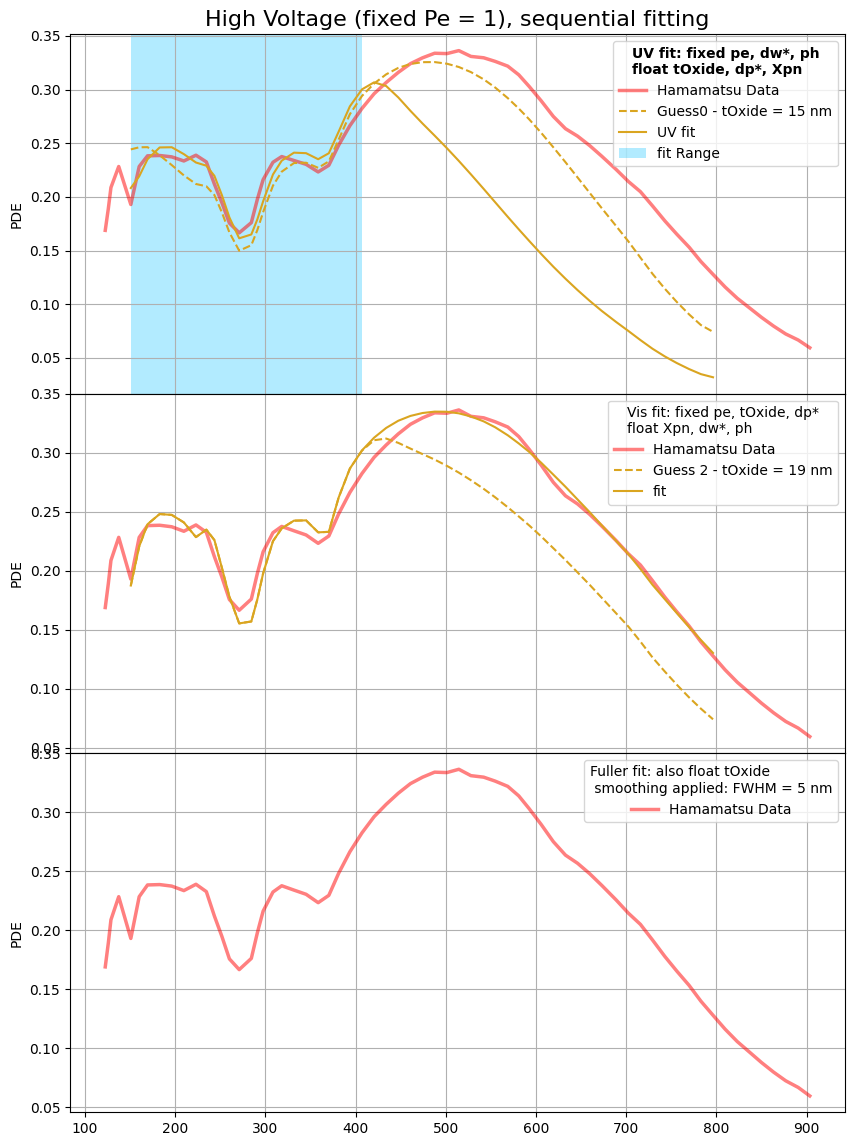

In [7]:
# repeat with Ham data, go thin

# -- load the data -- #
fitAngle = 0
voltages = df['Overvoltage'].unique()[2:]
fixedFF = 0.6
FWHMbeam = 5
sigmaBeam = FWHMbeam / (2 * np.sqrt(2 * np.log(2)))

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize = (10, 14))
axes = [ax1, ax2, ax3]

xHam, yHam = OpticsData().Load_Ham_data()

[ax.plot(xHam, yHam, color = "red", linewidth = 2.5, alpha = 0.5, label = "Hamamatsu Data") for ax in axes]

## fit options
cfit_opts = {"maxfev": 10000, "xtol": 1e-6, "ftol": 1e-6, "absolute_sigma":True}


# model breaks after 800
mask_full = (xHam > 150) & (xHam < 800)
xHam = xHam[mask_full]
yHam = yHam[mask_full]
yErr_ham = 0.05 * yHam

## doing UV fit
mask_uv =  (xHam < 420)
xHam_uv = xHam[mask_uv]
yHam_uv = yHam[mask_uv]

pm.bounds_dict = {"tOxide":(5, 300),
                  "dp_star":(0.0, 100),
                  "Xpn":(1e3, 5e3),
                  "dw_star":(1e3, 25e3),
                  "pe":(0.0, 1.0),
                  "ph":(0.0, 1)
                  }

for i, tOxide_guess in enumerate([15]):
    
    colMS = ms.allColsStr[i]
    print(f"========== Fit {i+1} ==========")
    
    # ---------------- UV Fit 1 - high voltage - fixed pe ----------------- #
    pm.guessUV_fpe = {"tOxide": tOxide_guess, "dp_star": 1.0, "Xpn": 2.5e3}
    pm.staticPars_uv_fpe = {"FF":fixedFF, "theta1":0, "dw_star": 5e3, "pe":0.9, "ph":0.0, "smoothSigma": 5}
    
    # pnTest = PNJunction(dp_star = pm.guessUV_fpe["dp_star"], Xpn = pm.guessUV_fpe["Xpn"], dw_star=pm.staticPars_uv_fpe["dw_star"])
    # print(pnTest.calcW_both(PhotonInfo(420, 0)))
    # print(PDE_wrapped_uv_fpe(420, **pm.guessUV_fpe))

    # get the guesses and bounds from the dictionairies
    pGuess_uv_fpe = tuple(pm.guessUV_fpe.values())
    lower_bounds_uv_fpe = [pm.bounds_dict[key][0] for key in pm.guessUV_fpe]
    upper_bounds_uv_fpe = [pm.bounds_dict[key][1] for key in pm.guessUV_fpe]

    # fitting and plotting
    ax1.plot(xHam, PDE_wrapped_uv_fpe(xHam, *pGuess_uv_fpe), linestyle = "--", color = colMS, label = f"Guess{i} - tOxide = {tOxide_guess:0.0f} nm") # plot guess
    popt_uv_fpe, pcov_uv_fpe = curve_fit(f=PDE_wrapped_uv_fpe, xdata=xHam_uv, ydata=yHam_uv, p0=pGuess_uv_fpe, bounds=(lower_bounds_uv_fpe, upper_bounds_uv_fpe))
    # plot the UV fit
    ax1.plot(xHam, PDE_wrapped_uv_fpe(xHam, *popt_uv_fpe), color = colMS, label = "UV fit")

    # uvFits_fpe.append([popt_uv_fpe, pcov_uv_fpe])
    print("UV fit(fixed pe, IR junction pars) results:", popt_uv_fpe)
    for i, key in enumerate(pm.guessUV_fpe):
        print(f"    {key}: {popt_uv_fpe[i]:0.2f}  +/- {np.sqrt(pcov_uv_fpe[i,i]):0.2f}")    
    fit_tOxide = popt_uv_fpe[0]
    fit_dp_star = popt_uv_fpe[1]
    fit_Xpn = popt_uv_fpe[2]
    
    # ---------------- Full fit - high voltage - fixed pe, tOxide ----------------- #
    pm.guessVis_fpe_junction = {"Xpn": fit_Xpn, "dw_star": pm.staticPars_uv_fpe["dw_star"], "ph":0.4}
    pm.staticPars_vis_junction = {"FF":0.6, "theta1":0.0, "tOxide": fit_tOxide, "dp_star": fit_dp_star, "pe":0.9} # handed straight to function
    
    pGuess_vis_fpe_junction = tuple(pm.guessVis_fpe_junction.values())
    lower_bounds_vis_fpe_junc = [pm.bounds_dict[key][0] for key in pm.guessVis_fpe_junction]
    upper_bounds_vis_fpe_junc = [pm.bounds_dict[key][1] for key in pm.guessVis_fpe_junction]
    
    ax2.plot(xHam, PDE_wrapped_vis_junction(xHam, *pGuess_vis_fpe_junction), color = colMS, linestyle = "--", label = f"Guess {i} - tOxide = {fit_tOxide:0.0f} nm") # plot guess
    popt_vis_fpe_junc, pcov_vis_fpe_junc = curve_fit(f=PDE_wrapped_vis_junction, xdata=xHam, ydata=yHam, p0=pGuess_vis_fpe_junction, bounds=(lower_bounds_vis_fpe_junc, upper_bounds_vis_fpe_junc), **cfit_opts)
    ax2.plot(xHam, PDE_wrapped_vis_junction(xHam, *popt_vis_fpe_junc), color = colMS, label = f"fit")
    
    print("Vis fit (fixed pe, dp*, tOxide) results:", popt_vis_fpe_junc)
    for i, key in enumerate(pm.guessVis_fpe_junction):
        print(f"    {key}: {popt_vis_fpe_junc[i]:0.2f}  +/- {np.sqrt(pcov_vis_fpe_junc[i,i]):0.2f}")
    
    fit2_Xpn = popt_vis_fpe_junc[0]
    fit2_dw_star = popt_vis_fpe_junc[1]
    fit2_ph = popt_vis_fpe_junc[2]
    
    # # ---------------- Full Fit 2 - high voltage - fixed pe, float tOxide ----------------- #
    # pm.guessVis_fpe1 = {"tOxide":fit_tOxide, "Xpn": fit2_Xpn, "dw_star": fit2_dw_star, "ph": fit2_ph}
    # pm.staticPars_vis_fpe1 = {"FF":0.6, "theta1":0.0, "dp_star": fit_dp_star, "pe":0.9} # handed straight to function
    
    # pGuess_vis_fpe1 = tuple(pm.guessVis_fpe1.values())
    # lower_bounds_vis_fpe1 = [pm.bounds_dict[key][0] for key in pm.guessVis_fpe1]
    # upper_bounds_vis_fpe1 = [pm.bounds_dict[key][1] for key in pm.guessVis_fpe1]
    
    # ax3.plot(xHam, PDE_wrapped_vis1(xHam, *pGuess_vis_fpe1), color = colMS, linestyle = "--", label = f"Guess {i} - tOxide = {fit_tOxide:0.1f} nm") # plot guess
    # popt_vis_fpe1, pcov_vis_fpe1 = curve_fit(f=PDE_wrapped_vis1, xdata=xHam, ydata=yHam, p0=pGuess_vis_fpe1, bounds=(lower_bounds_vis_fpe1, upper_bounds_vis_fpe1), **cfit_opts)
    # ax3.plot(xHam, PDE_wrapped_vis1(xHam, *popt_vis_fpe1), color = colMS, label = f"Fuller fit, tOxide = {popt_vis_fpe1[0]:0.1f} nm")
    # print("Free-er Vis fit (fixed pe, dp*) results:", popt_vis_fpe1)
    # for i, key in enumerate(pm.guessVis_fpe1):
    #     print(f"    {key}: {popt_vis_fpe1[i]:0.2f}  +/- {np.sqrt(pcov_vis_fpe1[i,i]):0.2f}")
    
    # chi2 = np.sum((PDE_wrapped_vis1(xHam, *popt_vis_fpe1) - yHam)**2 / yErr_ham**2)
    # chi2_red = chi2 / (len(xHam) - len(popt_vis_fpe1))
    
    # print(f"\nChi2: {chi2:0.2f}\nreduced: {chi2_red:0.2f} \n")
    # print("--------------------------")
 
    
ax1.set_title("High Voltage (fixed Pe = 1), sequential fitting", fontsize = 16)

ax1.axvspan(min(xHam_uv), max(xHam_uv), facecolor=ms.cf4.col, alpha=0.3, label = "fit Range")
leg = ax1.legend(title = "UV fit: fixed pe, dw*, ph\nfloat tOxide, dp*, Xpn")
plt.setp(leg.get_title(), weight='bold')

leg = ax2.legend(title = "Vis fit: fixed pe, tOxide, dp*\nfloat Xpn, dw*, ph")

ax3.legend(title = f"Fuller fit: also float tOxide\n smoothing applied: FWHM = {FWHMbeam:0.0f} nm")

for ax in axes:
    ax.grid()
    ax.set_ylabel("PDE")
    
# plt.tight_layout()
plt.subplots_adjust(hspace=0)
plt.show()